### 1. Подготовка окружения

Импортируем необходимые модули Python и классы банковских счетов. Определяем корневую директорию проекта, чтобы ноутбук мог обращаться к модулю с реализацией бизнес-логики.

Для денежных расчётов используем `Decimal`, а для построения графиков — `matplotlib`.

In [1]:
from pathlib import Path
import sys
from decimal import Decimal

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

sys.path.insert(0, str(PROJECT_ROOT / "src"))

from src.bank_account import BankAccount

### 2. Создание банковского счёта

Создаём объект класса `BankAccount`, передавая имя владельца и начальный баланс. Выводим владельца, автоматически присвоенный номер счёта и баланс.

Проверяем, что объект создаётся с корректными исходными данными и доступом к своим атрибутам.

In [2]:
account = BankAccount("Анна Иванова", 1000)

print(f"Владелец: {account.owner}")
print(f"Номер счёта: {account.account_number}")
print(f"Начальный баланс: {account.balance:.2f}")

Владелец: Анна Иванова
Номер счёта: ACC-1000
Начальный баланс: 1000.00


### 3. Успешные операции пополнения и снятия

Выполняем несколько операций с положительными суммами. Проверяем, что пополнения увеличивают баланс, снятия уменьшают его, а дробные денежные суммы обрабатываются без ошибок округления благодаря использованию `Decimal`.

In [3]:
account.deposit(500)
account.deposit(250.50)

account.withdraw(300)
account.withdraw(100)

print(f"Текущий баланс: {account.get_balance():.2f}")
assert account.balance == Decimal("1350.50")

Текущий баланс: 1350.50


### 4. Обработка неуспешной операции

Пытаемся снять сумму, превышающую доступный баланс. Проверяем, что операция отклонена, баланс не изменился, а неуспешная попытка сохранена в истории со статусом `fail`.

In [4]:
result = account.withdraw(2000)
balance_before = account.balance
result = account.withdraw(2000)

assert result is False
assert account.balance == balance_before
assert account.get_history()[-1]["status"] == "fail"

print("Проверка неуспешного снятия пройдена")

print(f"Операция успешна: {result}")
print(f"Баланс после попытки: {account.balance:.2f}")


Проверка неуспешного снятия пройдена
Операция успешна: False
Баланс после попытки: 1350.50


### 5. Просмотр истории операций

Выводим полную историю счёта. Проверяем, что в ней отражены как успешные операции, так и отклонённая попытка снятия. Для каждой записи сохраняются тип операции, сумма, дата, статус и баланс после операции.

In [5]:
account.display_history()

История счёта ACC-1000 (base)
------------------------------------------------------------------------------------------
21.10.2026 14:07:52 | deposit          |     500.00 |    1500.00 | success | -
21.10.2026 14:07:52 | deposit          |     250.50 |    1750.50 | success | -
21.10.2026 14:07:52 | withdraw         |     300.00 |    1450.50 | success | -
21.10.2026 14:07:52 | withdraw         |     100.00 |    1350.50 | success | -
21.10.2026 14:07:52 | withdraw         |    2000.00 |    1350.50 | fail    | -
21.10.2026 14:07:52 | withdraw         |    2000.00 |    1350.50 | fail    | -


### 6. Автоматическая проверка операций и баланса

Используем `assert`, чтобы подтвердить правильность расчётов и сохранения истории. Проверяем количество записей, итоговый баланс и данные последней неуспешной операции.

Если хотя бы одно условие не выполняется, Python сообщит об ошибке проверки.

In [6]:
history = account.get_history()

assert len(history) == 6
assert account.balance == Decimal("1350.50")
assert history[-1]["operation"] == "withdraw"
assert history[-1]["status"] == "fail"
assert history[-1]["balance_after"] == Decimal("1350.50")

print("Все проверки пройдены!")

Все проверки пройдены!


### 7. Визуализация изменения баланса

Строим линейный график, где по оси X располагается время операции, а по оси Y — баланс после операции. График помогает визуально проверить, как пополнения и снятия влияют на состояние счёта.

Отклонённые операции также отображаются: они не изменяют баланс, поэтому соответствующая точка остаётся на прежнем уровне.

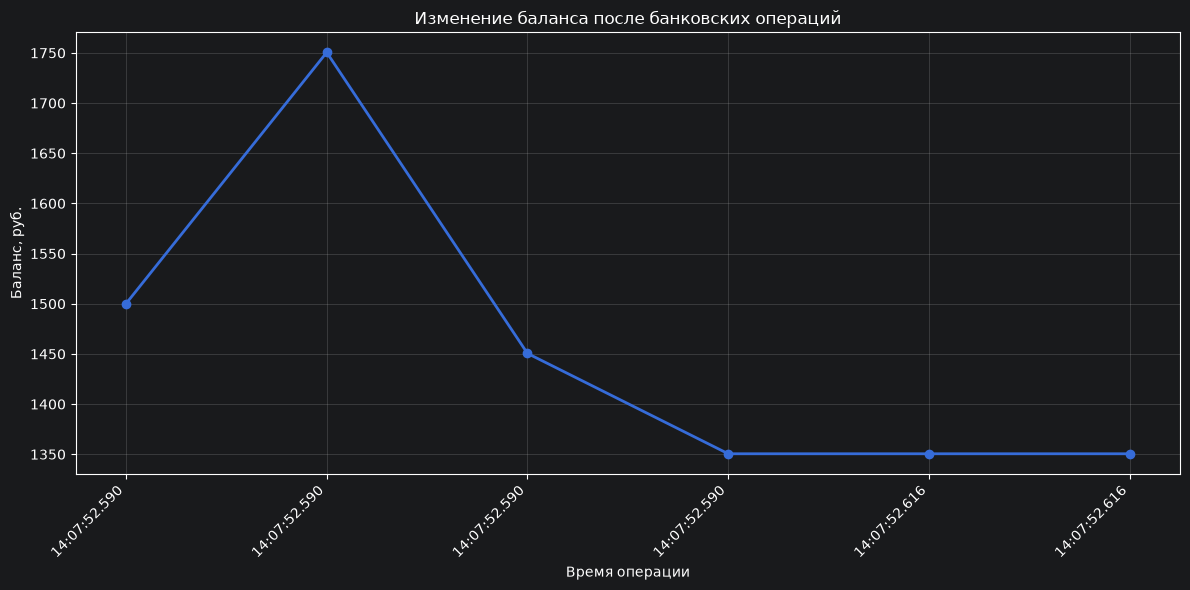

In [7]:

import matplotlib.pyplot as plt

history = sorted(
    account.get_history(),
    key=lambda record: record["date"]
)

operation_numbers = list(range(1, len(history) + 1))

operation_times = [
    record["date"].strftime("%H:%M:%S.%f")[:-3]
    for record in history
]

balances = [
    float(record["balance_after"])
    for record in history
]

plt.figure(figsize=(12, 6))

plt.plot(
    operation_numbers,
    balances,
    marker="o",
    linewidth=2
)

plt.xticks(
    operation_numbers,
    operation_times,
    rotation=45,
    ha="right"
)

plt.title("Изменение баланса после банковских операций")
plt.xlabel("Время операции")
plt.ylabel("Баланс, руб.")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 8. Создание счетов разных типов

Создаём расчётный и сберегательный счета. Проверяем, что каждому объекту присваивается соответствующий тип, а также что начальные балансы и номера доступны через атрибуты объекта.

Расчётный счёт предназначен для обычных пополнений и снятий. Сберегательный дополнительно поддерживает начисление процентов и ограничение суммы снятия.

In [8]:
from src.bank_account import CheckingAccount, SavingsAccount

checking = CheckingAccount("Anna Ivanova", 5000)
savings = SavingsAccount("Мария Смирнова", 10000)

print(checking.account_number, checking.account_type, checking.balance)
print(savings.account_number, savings.account_type, savings.balance)

assert checking.account_type == "checking"
assert savings.account_type == "savings"
assert checking.balance == 5000
assert savings.balance == 10000
assert checking.account_number != savings.account_number

ACC-1001 checking 5000
ACC-1002 savings 10000


### 9. Пополнение и начисление процентов

Выполняем операции на обоих счетах. На сберегательном счёте дополнительно начисляем проценты по ставке 7% от текущего баланса.

Проверяем, что начисленные проценты увеличивают баланс, а операция отражается в истории с типом `interest`.

In [9]:
checking.deposit(1500)
checking.withdraw(1000)

savings.deposit(2000)

interest = savings.add_interest(7)
print(f"Начислено процентов: {interest:.2f}")

print(f"Баланс расчётного счёта: {checking.balance:.2f}")
print(f"Баланс сберегательного счёта: {savings.balance:.2f}")

assert checking.balance == 5500
assert interest == 840.00
assert savings.balance == 12840.00
assert savings.get_history()[-1]["operation"] == "interest"

Начислено процентов: 840.00
Баланс расчётного счёта: 5500.00
Баланс сберегательного счёта: 12840.00


### 10. Проверка ограничения снятия со сберегательного счёта

Проверяем правило, по которому за одну операцию можно снять не более 50% текущего баланса. Сумма 7000 превышает допустимый лимит 6420, поэтому операция должна завершиться отказом без изменения баланса. Неуспешная попытка должна попасть в историю.

In [10]:
balance_before = savings.balance

result = savings.withdraw(7000)

print(f"Операция успешна: {result}")
print(f"Баланс до попытки: {balance_before:.2f}")
print(f"Баланс после попытки: {savings.balance:.2f}")

assert result is False
assert savings.balance == balance_before
assert savings.get_history()[-1]["status"] == "fail"

Операция успешна: False
Баланс до попытки: 12840.00
Баланс после попытки: 12840.00


In [11]:
limit_account = SavingsAccount("Olga Petrova", 10000)

result = limit_account.withdraw(5000)

assert result is True
assert limit_account.balance == 5000
assert limit_account.get_history()[-1]["status"] == "success"

print("Снятие ровно 50% баланса разрешено")

Снятие ровно 50% баланса разрешено


### 11. Аналитика крупных операций

Получаем последние три успешные операции с суммой не менее 500. Проверяем, что аналитика исключает неуспешные операции и операции ниже установленного порога, а результат содержит не более заданного количества записей.

In [12]:
large_operations = savings.get_large_operations(
    threshold=500,
    n=3,
)

for operation in large_operations:
    print(
        operation["date"].strftime("%d.%m.%Y %H:%M:%S"),
        operation["operation"],
        operation["amount"],
        operation["status"],
    )

assert len(large_operations) <= 3
assert all(op["status"] == "success" for op in large_operations)
assert all(op["amount"] >= 500 for op in large_operations)

print("Проверка аналитики пройдена")


21.10.2026 14:07:52 deposit 2000 success
21.10.2026 14:07:52 interest 840.00 success
Проверка аналитики пройдена


### 12. Проверка валидации входных данных

Передаём некорректное имя владельца и отрицательную сумму пополнения. Проверяем, что модель отклоняет неверные данные с помощью исключений, а некорректные операции не выполняются.

In [13]:
invalid_name_rejected = False

try:
    CheckingAccount("anna ivanova", 1000)
except ValueError:
    invalid_name_rejected = True

assert invalid_name_rejected

invalid_amount_rejected = False

try:
    checking.deposit(-100)
except ValueError:
    invalid_amount_rejected = True

assert invalid_amount_rejected

print("Проверки валидации пройдены")

Проверки валидации пройдены


### 13. Визуализация операций сберегательного счёта

Строим график баланса сберегательного счёта после каждой операции. Отдельно виден эффект пополнения, начисления процентов и отклонённой попытки снятия, которая не меняет баланс.

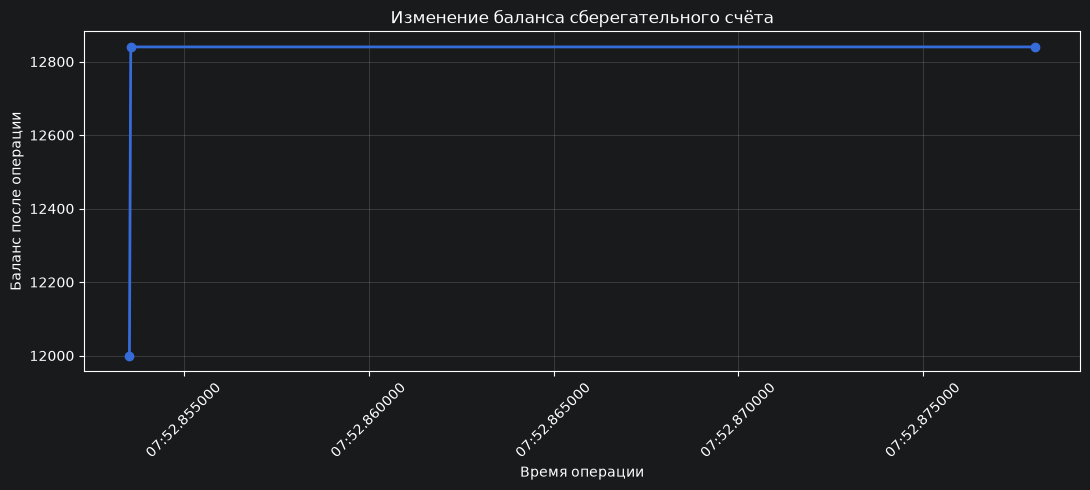

In [14]:
import matplotlib.pyplot as plt

history = savings.get_history()

dates = [record["date"] for record in history]
balances = [
    float(record["balance_after"])
    for record in history
]

plt.figure(figsize=(11, 5))
plt.plot(dates, balances, marker="o", linewidth=2)

plt.title("Изменение баланса сберегательного счёта")
plt.xlabel("Время операции")
plt.ylabel("Баланс после операции")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 14. Успешный перевод между счетами

Переводим 500 с расчётного счёта на сберегательный. Проверяем, что баланс отправителя уменьшился, баланс получателя увеличился на ту же сумму, а обе записи в истории имеют одинаковый идентификатор перевода и статус `success`.

In [15]:
checking_before = checking.balance
savings_before = savings.balance

result = checking.transfer_to(savings, 500)

print(f"Перевод выполнен: {result}")
print(f"Расчётный счёт: {checking.balance:.2f}")
print(f"Сберегательный счёт: {savings.balance:.2f}")

assert checking.balance == checking_before - 500
assert savings.balance == savings_before + 500

outgoing = checking.get_history()[-1]
incoming = savings.get_history()[-1]

assert outgoing["transfer_id"] == incoming["transfer_id"]
assert outgoing["status"] == incoming["status"] == "success"

Перевод выполнен: True
Расчётный счёт: 5000.00
Сберегательный счёт: 13340.00


### 15. Обработка неуспешного перевода

Пытаемся перевести со сберегательного счёта сумму, превышающую допустимый лимит снятия. Проверяем, что операция отклонена, балансы обоих счетов не меняются, а в обеих историях появляются связанные записи со статусом `fail`.

In [16]:
from decimal import Decimal

savings_before = savings.balance
checking_before = checking.balance

result = savings.transfer_to(checking, savings.balance * Decimal("0.75"))

print(f"Перевод выполнен: {result}")

assert result is False
assert savings.balance == savings_before
assert checking.balance == checking_before
assert savings.get_history()[-1]["status"] == "fail"
assert checking.get_history()[-1]["status"] == "fail"
outgoing = savings.get_history()[-1]
incoming = checking.get_history()[-1]

assert outgoing["transfer_id"] == incoming["transfer_id"]
assert outgoing["transfer_id"] is not None

Перевод выполнен: False


### 16. Итоговая история расчётного и сберегательного счетов

Выводим полные истории обоих счетов после переводов. Проверяем, что успешные и неуспешные переводы отражаются в истории каждого участника.

In [17]:
print("Расчётный счёт")
checking.display_history()

print("\nСберегательный счёт")
savings.display_history()

Расчётный счёт
История счёта ACC-1001 (checking)
------------------------------------------------------------------------------------------
21.10.2026 14:07:52 | deposit          |    1500.00 |    6500.00 | success | -
21.10.2026 14:07:52 | withdraw         |    1000.00 |    5500.00 | success | -
21.10.2026 14:07:53 | transfer_out     |     500.00 |    5000.00 | success | 044c45dd-69b3-4694-8221-f368487dff9a
21.10.2026 14:07:53 | transfer_in      |   10005.00 |    5000.00 | fail    | df94c244-f70e-4ad8-b9e9-423f23b3e4a6

Сберегательный счёт
История счёта ACC-1002 (savings)
------------------------------------------------------------------------------------------
21.10.2026 14:07:52 | deposit          |    2000.00 |   12000.00 | success | -
21.10.2026 14:07:52 | interest         |     840.00 |   12840.00 | success | -
21.10.2026 14:07:52 | withdraw         |    7000.00 |   12840.00 | fail    | -
21.10.2026 14:07:53 | transfer_in      |     500.00 |   13340.00 | success | 044c45dd-69b3-4

### 17. Подготовка счетов для импорта данных

Создаём отдельные объекты расчётного и сберегательного счетов для загрузки внешней истории. Указываем номера счетов, которые присутствуют в CSV, чтобы загрузчик мог выбрать только относящиеся к ним операции.

Начальные балансы задаём до импорта. Затем они будут изменяться при последовательном применении принятых успешных операций.

In [18]:
from pathlib import Path

csv_path = Path("transactions_dirty.csv")

checking = CheckingAccount("Anna Ivanova", 1200)
checking.account_number = "ACC-100001"

savings = SavingsAccount("Maria Smirnova", 1500)
savings.account_number = "ACC-100002"

### 18. Импорт и очистка истории из CSV

Загружаем операции из общего CSV-файла отдельно в расчётный и сберегательный счета. Загрузчик выбирает записи по номеру счёта и типу счёта, проверяет формат данных, применяет валидные операции и возвращает отчёт о принятых и отклонённых строках.

После импорта выводим количество обработанных записей и пересчитанные балансы.

In [19]:
checking_report = checking.load_history_csv(csv_path)
savings_report = savings.load_history_csv(csv_path)

print("Расчётный счёт")
print(f"Принято: {checking_report['accepted']}")
print(f"Отклонено: {checking_report['rejected']}")
print(f"Баланс: {checking.balance:.2f}")

print("\nСберегательный счёт")
print(f"Принято: {savings_report['accepted']}")
print(f"Отклонено: {savings_report['rejected']}")
print(f"Баланс: {savings.balance:.2f}")

Расчётный счёт
Принято: 17
Отклонено: 9
Баланс: 4864.00

Сберегательный счёт
Принято: 18
Отклонено: 9
Баланс: 3991.24


### 19. Просмотр загруженной истории

Показываем первые пять операций, принятых для расчётного счёта. Выводим дату, тип операции, сумму, статус и баланс после операции. Это позволяет визуально проверить, что данные импортированы в правильной последовательности и баланс пересчитывается по истории.

In [20]:
for record in checking.get_history()[:5]:
    print(
        record["date"].strftime("%d.%m.%Y %H:%M:%S"),
        record["operation"],
        record["amount"],
        record["status"],
        record["balance_after"],
    )

27.09.2025 22:17:26 deposit 921.0 success 2121.0
27.09.2025 22:17:26 deposit 607.0 success 2728.0
28.09.2025 22:17:26 deposit 488.0 success 3216.0
28.09.2025 22:17:00 deposit 129.0 success 3345.0
29.09.2025 22:17:26 deposit 880.0 success 4225.0


### 20. Отчёт об очистке данных

Выводим количество принятых и отклонённых строк для каждого счёта. Для каждой отклонённой строки показываем номер исходной строки и причину отказа: некорректная дата, недопустимый тип операции, неверный статус, некорректная сумма или другая ошибка валидации.

Отчёт позволяет понять не только итог очистки, но и качество исходных данных.

In [21]:
for account_name, report in [
    ("Расчётный счёт", checking_report),
    ("Сберегательный счёт", savings_report),
]:
    print(f"\n{account_name}:")
    print(f"Принято строк: {report['accepted']}")
    print(f"Отклонено строк: {report['rejected']}")

    for error in report["errors"]:
        print(f"Строка {error['row']}: {error['reason']}")


Расчётный счёт:
Принято строк: 17
Отклонено строк: 9
Строка 7: Пустая сумма
Строка 10: Недопустимая операция: ''
Строка 12: Недопустимая операция: 'interest'
Строка 15: некорректная дата
Строка 17: Недопустимая операция: 'diposit'
Строка 18: Недопустимая операция: 'interest'
Строка 19: некорректная дата
Строка 26: Некорректный статус: 'succes'
Строка 106: Повторяющаяся строка

Сберегательный счёт:
Принято строк: 18
Отклонено строк: 9
Строка 30: некорректная дата
Строка 31: Пустая сумма
Строка 35: Сумма операции должна быть положительной
Строка 39: Недопустимая операция: 'diposit'
Строка 46: Сумма операции должна быть положительной
Строка 48: Некорректный статус: 'succes'
Строка 50: Недопустимая операция: 'wdraw'
Строка 102: Повторяющаяся строка
Строка 105: Повторяющаяся строка


### 21. Табличное представление ошибок импорта

Преобразуем списки ошибок в DataFrame Pandas, чтобы удобно анализировать отклонённые строки и причины. Добавляем столбец с типом счёта, для которого выполнялся импорт.

In [22]:
import pandas as pd

errors = (
    [{"account": "checking", **error}
     for error in checking_report["errors"]]
    + [{"account": "savings", **error}
       for error in savings_report["errors"]]
)

errors_df = pd.DataFrame(errors)
display(errors_df)

,account,row,reason
0,checking,7,Пустая сумма
1,checking,10,Недопустимая операция: ''
2,checking,12,Недопустимая операция: 'interest'
3,checking,15,некорректная дата
4,checking,17,Недопустимая операция: 'diposit'
5,checking,18,Недопустимая операция: 'interest'
6,checking,19,некорректная дата
7,checking,26,Некорректный статус: 'succes'
8,checking,106,Повторяющаяся строка
9,savings,30,некорректная дата


### 22. Проверка корректности загруженных данных

Проверяем, что операции каждого счёта соответствуют его типу. Расчётный счёт не должен содержать начисления процентов, а сберегательный может содержать операции `deposit`, `withdraw` и `interest`.

Дополнительно убеждаемся, что загрузка обработала записи и сформировала отчёт об очистке.

In [23]:
assert checking.account_type == "checking"
assert savings.account_type == "savings"

assert checking_report["accepted"] + checking_report["rejected"] > 0
assert savings_report["accepted"] + savings_report["rejected"] > 0

assert all(
    record["operation"] in {"deposit", "withdraw"}
    for record in checking.get_history()
)

assert all(
    record["operation"] in {"deposit", "withdraw", "interest"}
    for record in savings.get_history()
)

assert all(
    error["reason"]
    for error in checking_report["errors"] + savings_report["errors"]
)

assert checking_report["rejected"] == len(checking_report["errors"])
assert savings_report["rejected"] == len(savings_report["errors"])
print("Проверки пройдены")

Проверки пройдены
